# E-commerce Sales & Profitability Analysis
Where does a retailer make money, where does it lose it, and why?

**Dataset:** Superstore (9,994 order lines, 2015-2018). **Tools:** Python, SQL (SQLite), Pandas, Seaborn, Plotly.

Run the cells from top to bottom (Shift + Enter on each cell). The last code cells create `outputs/dashboard.html`.

### Imports

In [1]:
import json
import os
import sqlite3
import warnings

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
NAVY, RED = "#1F3864", "#C00000"

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
RAW_FILE = os.path.join(HERE, "data", "superstore_raw.csv")
OUT = os.path.join(HERE, "outputs")
CHARTS = os.path.join(OUT, "charts")
os.makedirs(CHARTS, exist_ok=True)

summary = []  # lines we will write into outputs/summary.md


def say(text=""):
    print(text)
    summary.append(text)

### STEP 1 - Load and split the raw file

In [2]:
# The raw CSV is really THREE tables stacked one under the other:
#   rows 1..9,994   -> Orders   (one row per product in an order)
#   then            -> People   (4 regional managers)
#   then            -> Returns  (order IDs that were returned)
say("# Sales & Profitability Analysis - Results Summary\n")
raw = pd.read_csv(RAW_FILE, dtype=str)  # read everything as text first, to be safe
i_people = raw.index[raw["Row ID"] == "Person"][0]
i_returns = raw.index[raw["Row ID"] == "Returned"][0]

orders = raw.iloc[:i_people].copy()
managers = raw.iloc[i_people + 1:i_returns, :2].copy()
managers.columns = ["person", "region"]
returns = raw.iloc[i_returns + 1:, :2].copy()
returns.columns = ["returned", "order_id"]
say(f"- Raw file: **{len(raw):,}** rows = **{len(orders):,}** order lines "
    f"+ **{len(managers)}** managers + **{len(returns)}** return records\n")

# Sales & Profitability Analysis - Results Summary

- Raw file: **10,800** rows = **9,994** order lines + **4** managers + **800** return records



### STEP 2 - Clean

In [3]:
orders.columns = ["row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
                  "customer_name", "segment", "country", "city", "state", "postal_code", "region",
                  "product_id", "category", "sub_category", "product_name", "sales", "quantity",
                  "discount", "profit"]
for col in ["sales", "quantity", "discount", "profit"]:
    orders[col] = pd.to_numeric(orders[col])
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%m/%d/%Y")
orders["ship_date"] = pd.to_datetime(orders["ship_date"], format="%m/%d/%Y")

# Postal codes lost their leading zeros (e.g. 5401 should be 05401). Put them back.
missing_postal = int(orders["postal_code"].isna().sum())
orders["postal_code"] = orders["postal_code"].str.replace(r"\.0$", "", regex=True).str.zfill(5)
# The missing ones are all Burlington, Vermont, whose real postal code is 05401.
orders["postal_code"] = orders["postal_code"].fillna("05401")
missing_other = int(orders.isna().sum().sum())

# One order line appears twice (same everything except the row number). Remove it.
dedupe_cols = [c for c in orders.columns if c != "row_id"]
duplicates = int(orders.duplicated(subset=dedupe_cols).sum())
orders = orders.drop_duplicates(subset=dedupe_cols).reset_index(drop=True)
bad_ship = int((orders["ship_date"] < orders["order_date"]).sum())
returns_unique = returns.drop_duplicates(subset="order_id")

orders["order_year"] = orders["order_date"].dt.year
orders["order_month"] = orders["order_date"].dt.strftime("%Y-%m")
orders["ship_days"] = (orders["ship_date"] - orders["order_date"]).dt.days
orders["profit_margin_pct"] = (orders["profit"] / orders["sales"] * 100).round(2)

say("## Data cleaning\n")
say(f"- Missing postal codes: **{missing_postal}** (all Burlington, Vermont, filled with 05401)")
say(f"- Other missing values: **{missing_other}**")
say(f"- Duplicate order lines removed: **{duplicates}** (leaves **{len(orders):,}** order lines)")
say(f"- Orders shipped before they were placed: **{bad_ship}**")
say(f"- Return records: **{len(returns)}**, unique returned orders: **{len(returns_unique)}** "
    f"(some orders had several returned products)")
say(f"- Date range: **{orders['order_date'].min():%d %b %Y}** to **{orders['order_date'].max():%d %b %Y}**\n")

## Data cleaning

- Missing postal codes: **11** (all Burlington, Vermont, filled with 05401)
- Other missing values: **0**
- Duplicate order lines removed: **1** (leaves **9,993** order lines)
- Orders shipped before they were placed: **0**
- Return records: **800**, unique returned orders: **296** (some orders had several returned products)
- Date range: **03 Jan 2015** to **30 Dec 2018**



### STEP 3 - SQL questions

In [4]:
say("## SQL findings\n")
db_path = os.path.join(OUT, "sales.db")
if os.path.exists(db_path):
    os.remove(db_path)
con = sqlite3.connect(db_path)
sql_orders = orders.copy()
sql_orders["order_date"] = sql_orders["order_date"].dt.strftime("%Y-%m-%d")  # SQL likes ISO dates
sql_orders["ship_date"] = sql_orders["ship_date"].dt.strftime("%Y-%m-%d")
sql_orders.to_sql("orders", con, index=False)
managers.to_sql("managers", con, index=False)
returns_unique[["order_id"]].to_sql("returns", con, index=False)

queries = {
    "kpis": """
        SELECT ROUND(SUM(sales), 0)                          AS total_sales,
               ROUND(SUM(profit), 0)                         AS total_profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1)    AS profit_margin_pct,
               COUNT(DISTINCT order_id)                      AS orders,
               COUNT(DISTINCT customer_id)                   AS customers,
               ROUND(SUM(sales) / COUNT(DISTINCT order_id), 0) AS avg_order_value
        FROM orders;""",
    # Window function LAG() looks at the previous year's row
    "yearly_growth": """
        WITH yearly AS (
            SELECT strftime('%Y', order_date) AS year, SUM(sales) AS sales, SUM(profit) AS profit
            FROM orders GROUP BY year)
        SELECT year,
               ROUND(sales, 0)  AS sales,
               ROUND(profit, 0) AS profit,
               ROUND(100.0 * profit / sales, 1) AS margin_pct,
               ROUND(100.0 * (sales - LAG(sales) OVER (ORDER BY year))
                     / LAG(sales) OVER (ORDER BY year), 1) AS sales_growth_pct
        FROM yearly ORDER BY year;""",
    "category_performance": """
        SELECT category,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY category ORDER BY profit DESC;""",
    "loss_making_subcategories": """
        SELECT sub_category,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY sub_category
        HAVING SUM(profit) < 0
        ORDER BY profit;""",
    "subcategory_profit": """
        SELECT sub_category,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY sub_category ORDER BY profit DESC;""",
    # CASE WHEN puts each row into a discount "band"
    "discount_impact": """
        SELECT CASE WHEN discount = 0    THEN '1) No discount'
                    WHEN discount <= 0.2 THEN '2) 1-20%'
                    WHEN discount <= 0.4 THEN '3) 21-40%'
                    ELSE '4) Over 40%' END AS discount_band,
               COUNT(*) AS order_lines,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY discount_band ORDER BY discount_band;""",
    # JOIN with the managers table
    "region_and_manager": """
        SELECT m.person AS manager, o.region,
               ROUND(SUM(o.sales), 0)  AS sales,
               ROUND(SUM(o.profit), 0) AS profit,
               ROUND(100.0 * SUM(o.profit) / SUM(o.sales), 1) AS margin_pct
        FROM orders o JOIN managers m ON o.region = m.region
        GROUP BY m.person, o.region ORDER BY profit DESC;""",
    # LEFT JOIN with returns: which orders came back?
    "return_rate_by_category": """
        SELECT o.category,
               COUNT(DISTINCT o.order_id) AS orders,
               COUNT(DISTINCT CASE WHEN r.order_id IS NOT NULL THEN o.order_id END) AS returned_orders,
               ROUND(100.0 * COUNT(DISTINCT CASE WHEN r.order_id IS NOT NULL THEN o.order_id END)
                     / COUNT(DISTINCT o.order_id), 1) AS return_rate_pct
        FROM orders o LEFT JOIN returns r ON o.order_id = r.order_id
        GROUP BY o.category ORDER BY return_rate_pct DESC;""",
    # Why is one region weaker? Compare how much discount each region gives
    "discount_by_region": """
        SELECT region,
               ROUND(100.0 * AVG(discount), 1) AS avg_discount_pct,
               ROUND(100.0 * SUM(CASE WHEN discount > 0.2 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_lines_over_20pct_discount,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY region ORDER BY avg_discount_pct DESC;""",
    "worst_states_by_profit": """
        SELECT state,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY state ORDER BY profit LIMIT 5;""",
    "top_states_by_sales": """
        SELECT state,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit,
               ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
        FROM orders GROUP BY state ORDER BY sales DESC LIMIT 5;""",
    "worst_products": """
        SELECT product_name,
               ROUND(SUM(sales), 0)  AS sales,
               ROUND(SUM(profit), 0) AS profit
        FROM orders GROUP BY product_name ORDER BY profit LIMIT 5;""",
    # Window functions again: rank customers, then measure the 80/20 rule
    "customer_concentration": """
        WITH cust AS (
            SELECT customer_id, SUM(sales) AS sales FROM orders GROUP BY customer_id),
        ranked AS (
            SELECT sales,
                   ROW_NUMBER() OVER (ORDER BY sales DESC) AS rank_no,
                   COUNT(*)     OVER ()                    AS n_customers,
                   SUM(sales)   OVER (ORDER BY sales DESC) AS running_sales,
                   SUM(sales)   OVER ()                    AS all_sales
            FROM cust)
        SELECT MAX(n_customers) AS customers,
               ROUND(100.0 * MAX(running_sales) / MAX(all_sales), 1) AS sales_share_of_top_20pct_customers
        FROM ranked WHERE rank_no <= n_customers * 0.2;""",
    "shipping_speed": """
        SELECT ship_mode,
               COUNT(*) AS order_lines,
               ROUND(AVG(julianday(ship_date) - julianday(order_date)), 1) AS avg_days_to_ship
        FROM orders GROUP BY ship_mode ORDER BY avg_days_to_ship;""",
    "best_months_of_year": """
        WITH monthly AS (
            SELECT strftime('%Y-%m', order_date) AS ym, strftime('%m', order_date) AS month_no,
                   SUM(sales) AS sales
            FROM orders GROUP BY ym)
        SELECT month_no, ROUND(AVG(sales), 0) AS avg_monthly_sales
        FROM monthly GROUP BY month_no ORDER BY avg_monthly_sales DESC LIMIT 4;""",
}
sql = {}
for name, q in queries.items():
    result = pd.read_sql_query(q, con)
    sql[name] = result
    display = result.copy()
    for c in display.columns:  # show whole numbers without decimals (e.g. 2297201 not 2.2972e+06)
        if display[c].dtype == float and display[c].notna().all() and (display[c] % 1 == 0).all():
            display[c] = display[c].astype("int64")
    display = display.astype(object).where(display.notna(), "-")
    result.to_csv(os.path.join(OUT, f"sql_{name}.csv"), index=False)
    say(f"**{name.replace('_', ' ').title()}**\n")
    say(display.to_markdown(index=False))
    say()
con.close()

## SQL findings

**Kpis**

|   total_sales |   total_profit |   profit_margin_pct |   orders |   customers |   avg_order_value |
|--------------:|---------------:|--------------------:|---------:|------------:|------------------:|
|       2296919 |         286409 |                12.5 |     5009 |         793 |               459 |

**Yearly Growth**

|   year |   sales |   profit |   margin_pct | sales_growth_pct   |
|-------:|--------:|---------:|-------------:|:-------------------|
|   2015 |  483966 |    49556 |         10.2 | -                  |
|   2016 |  470533 |    61619 |         13.1 | -2.8               |
|   2017 |  609206 |    81795 |         13.4 | 29.5               |
|   2018 |  733215 |    93439 |         12.7 | 20.4               |

**Category Performance**

| category        |   sales |   profit |   margin_pct |
|:----------------|--------:|---------:|-------------:|
| Technology      |  836154 |   145455 |         17.4 |
| Office Supplies |  719047 |   122491 |    

**Loss Making Subcategories**



| sub_category   |   sales |   profit |   margin_pct |
|:---------------|--------:|---------:|-------------:|
| Tables         |  206966 |   -17725 |         -8.6 |
| Bookcases      |  114880 |    -3473 |         -3   |
| Supplies       |   46674 |    -1189 |         -2.5 |

**Subcategory Profit**

| sub_category   |   sales |   profit |   margin_pct |
|:---------------|--------:|---------:|-------------:|
| Copiers        |  149528 |    55618 |         37.2 |
| Phones         |  330007 |    44516 |         13.5 |
| Accessories    |  167380 |    41937 |         25.1 |
| Paper          |   78479 |    34054 |         43.4 |
| Binders        |  203413 |    30222 |         14.9 |
| Chairs         |  328168 |    26602 |          8.1 |
| Storage        |  223844 |    21279 |          9.5 |
| Appliances     |  107532 |    18138 |         16.9 |
| Furnishings    |   91705 |    13059 |         14.2 |
| Envelopes      |   16476 |     6964 |         42.3 |
| Art            |   27119 |     6528 |

### STEP 4 - Charts

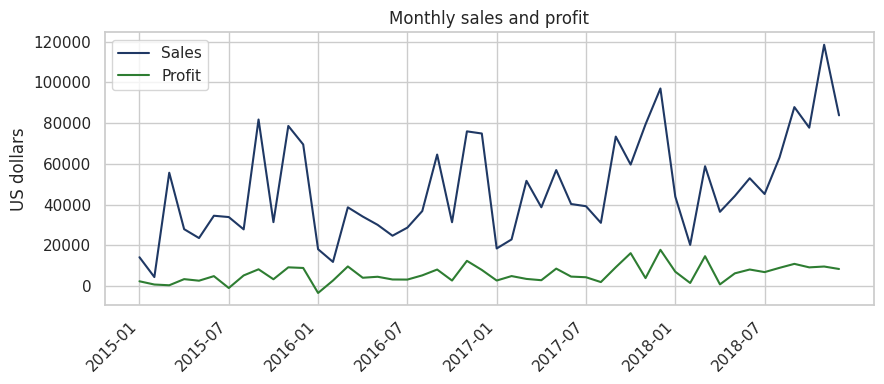

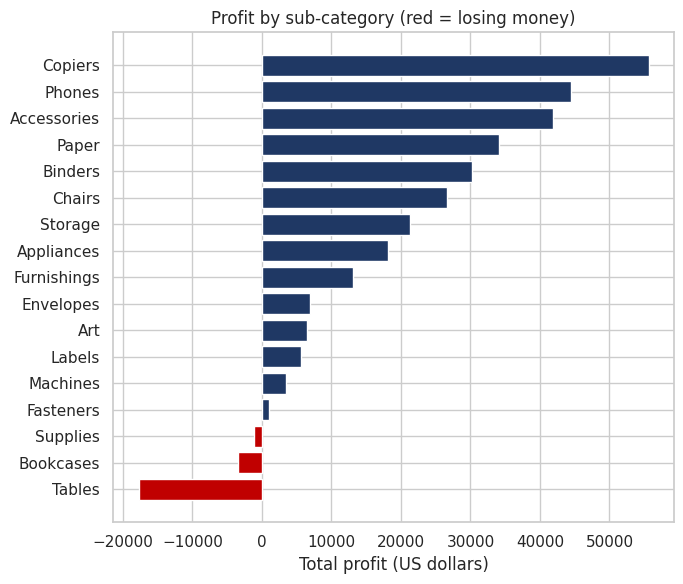

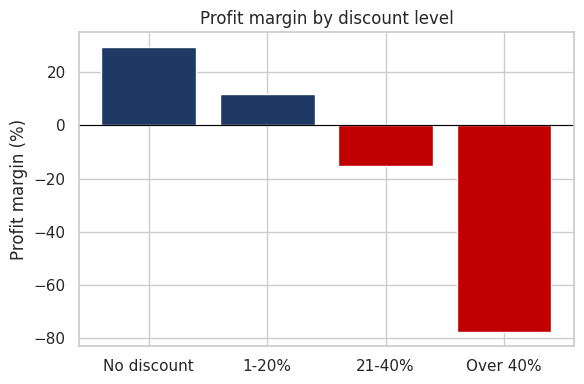

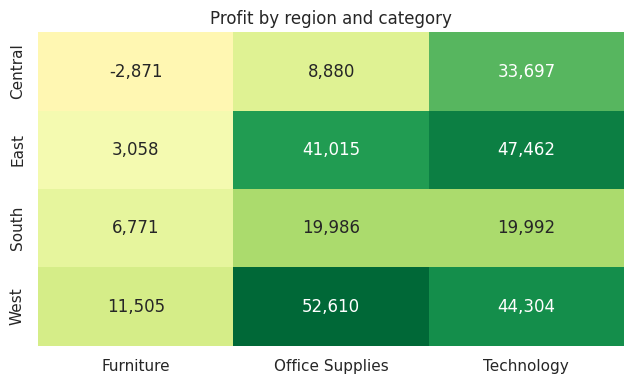

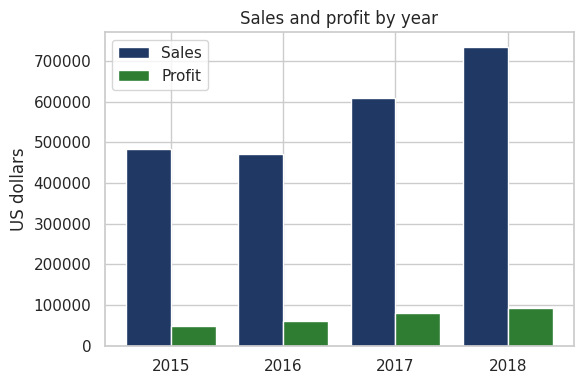

In [5]:
def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, name), dpi=150)
    plt.show()


monthly = orders.groupby("order_month")[["sales", "profit"]].sum().reset_index()
plt.figure(figsize=(9, 4))
plt.plot(monthly["order_month"], monthly["sales"], color=NAVY, label="Sales")
plt.plot(monthly["order_month"], monthly["profit"], color="#2E7D32", label="Profit")
plt.xticks(monthly["order_month"][::6], rotation=45, ha="right")
plt.title("Monthly sales and profit"); plt.ylabel("US dollars"); plt.legend()
save("01_monthly_sales_profit.png")

sub = sql["subcategory_profit"].sort_values("profit")
plt.figure(figsize=(7, 6))
plt.barh(sub["sub_category"], sub["profit"], color=[RED if p < 0 else NAVY for p in sub["profit"]])
plt.title("Profit by sub-category (red = losing money)"); plt.xlabel("Total profit (US dollars)")
save("02_subcategory_profit.png")

disc = sql["discount_impact"].copy()
disc["discount_band"] = disc["discount_band"].str[3:]
plt.figure(figsize=(6, 4))
plt.bar(disc["discount_band"], disc["margin_pct"], color=[RED if m < 0 else NAVY for m in disc["margin_pct"]])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Profit margin by discount level"); plt.ylabel("Profit margin (%)")
save("03_discount_vs_margin.png")

pivot = orders.pivot_table(index="region", columns="category", values="profit", aggfunc="sum").round(0)
plt.figure(figsize=(6.5, 4))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, cbar=False)
plt.title("Profit by region and category"); plt.xlabel(""); plt.ylabel("")
save("04_region_category_heatmap.png")

yr = sql["yearly_growth"]
x = range(len(yr))
plt.figure(figsize=(6, 4))
plt.bar([i - 0.2 for i in x], yr["sales"], width=0.4, color=NAVY, label="Sales")
plt.bar([i + 0.2 for i in x], yr["profit"], width=0.4, color="#2E7D32", label="Profit")
plt.xticks(list(x), yr["year"]); plt.title("Sales and profit by year"); plt.ylabel("US dollars"); plt.legend()
save("05_yearly_sales_profit.png")

### STEP 5 - Interactive dashboard

In [6]:
import plotly  # only needed to get the Plotly JavaScript file

PLOTLY_JS = open(os.path.join(os.path.dirname(plotly.__file__), "package_data", "plotly.min.js"),
                 encoding="utf-8").read()
band = pd.cut(orders["discount"], [-1, 0, 0.2, 0.4, 1], labels=["No discount", "1-20%", "21-40%", "Over 40%"])
d = pd.DataFrame({
    "ym": orders["order_month"], "year": orders["order_year"], "region": orders["region"],
    "state": orders["state"], "category": orders["category"], "sub": orders["sub_category"],
    "band": band.astype(str), "sales": orders["sales"].round(2), "profit": orders["profit"].round(2),
    "order": pd.factorize(orders["order_id"])[0], "cust": pd.factorize(orders["customer_id"])[0],
})
data_json = json.dumps({"cols": list(d.columns), "rows": d.values.tolist()}, separators=(",", ":"))
template = open(os.path.join(HERE, "dashboard_template.html"), encoding="utf-8").read()
html = template.replace("__PLOTLY__", PLOTLY_JS).replace("__DATA__", data_json)
with open(os.path.join(OUT, "dashboard.html"), "w", encoding="utf-8") as f:
    f.write(html)
say("Interactive dashboard saved: **outputs/dashboard.html**\n")

Interactive dashboard saved: **outputs/dashboard.html**



### STEP 6 - Save summary

In [7]:
with open(os.path.join(OUT, "summary.md"), "w") as f:
    f.write("\n".join(summary))
print("\nDONE! Open outputs/dashboard.html in your browser, and look inside the 'outputs' folder.")


DONE! Open outputs/dashboard.html in your browser, and look inside the 'outputs' folder.
